# Cross-validation across Functions 1-8

Compare the same Gaussian-process kernel candidates across all eight benchmark functions using shared, shuffled five-fold cross-validation within each function. The notebook reports fold-level predictive metrics and visualizes normalized error and uncertainty coverage.

Kernel rankings are comparisons on the supplied observations, not evidence of global optimization performance.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    ExpSineSquared,
    Matern,
    RBF,
    RationalQuadratic,
    WhiteKernel,
)

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.validation import cross_validate_kernels

CURRENT_WEEK = 4
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_IDS = tuple(FUNCTION_SPECS)
N_SPLITS = 5
LENGTH_CAPS = {
    1: 31.622776601683793,
    2: 31.622776601683793,
    3: 31.622776601683793,
    4: 10.0,
    5: 100.0,
    6: 31.622776601683793,
    7: 31.622776601683793,
    8: 100.0,
}
plt.style.use("seaborn-v0_8-whitegrid")

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


## Load observations and define kernels

As in Notebook 00, `load_weekly_history` validates weekly inputs, predictions, and outcomes through `CURRENT_WEEK`. `historical_results` selects `WEEKS` from `history.records` for inspecting historical predictions. Cross-validation uses `history.observations`, including initial rows and all evaluations through `CURRENT_WEEK`, not just the weekly records. Matérn and RBF use ARD length scales; scikit-learn's Rational Quadratic kernel is isotropic. Every kernel's length-scale bound uses the corresponding `LENGTH_CAPS[function_id]`; Exp-Sine-Squared periodicity retains its separate bounds. Each function's outputs are standardized during GP fitting.

### Exp-Sine-Squared kernel

This periodic candidate learns a shared period and length scale across input coordinates. It is most useful when the function has repeating structure; its results here are a comparison, not an assumption that every function is periodic.

In [2]:
historical_results = history.records.loc[history.records.week.isin(WEEKS)].copy()
observations_by_function = history.observations
data_summary = pd.DataFrame(
    [
        {
            "function_id": function_id,
            "observations": len(observations.inputs),
            "dimensions": observations.dimension,
            "output_std": float(np.std(observations.outputs)),
        }
        for function_id, observations in observations_by_function.items()
    ]
)
if (data_summary["observations"] < N_SPLITS).any():
    raise ValueError(f"Each function needs at least {N_SPLITS} observations for this comparison.")

display(historical_results)
display(data_summary)

,function_id,week,candidate,previous_best,expected_best,observed_best,expected_mean,expected_std,observed_output,residual,acquisition_score,acquisition_settings
0,1,1,"(0.835456, 0.75533)",7.710875e-16,1.189376e-03,7.710875e-16,1.159986e-03,0.000822,-3.459337e-42,-1.411377,0.002771,"{'name': 'ucb', 'kappa': 1.96}"
1,2,1,"(0.802058, 0.932779)",6.112052e-01,6.443316e-01,6.112052e-01,5.235641e-01,0.170883,1.263410e-01,-2.324530,0.858495,"{'name': 'ucb', 'kappa': 1.96}"
2,3,1,"(0.194638, 0.363906, 0.466721)",-3.483531e-02,-1.968917e-02,-5.894718e-03,-7.258401e-02,0.076102,-5.894718e-03,0.876316,0.076576,"{'name': 'ucb', 'kappa': 1.96}"
3,4,1,"(0.528998, 0.424017, 0.506366, 0.277697)",-4.025542e+00,-3.464557e+00,-3.336386e+00,-8.973412e+00,5.530818,-3.336386e+00,1.019203,1.866991,"{'name': 'ucb', 'kappa': 1.96}"
4,5,1,"(0.29667, 0.806944, 0.906495, 0.936907)",1.088860e+03,1.090590e+03,1.397545e+03,6.895015e+02,200.322259,1.397545e+03,3.534523,1082.133083,"{'name': 'ucb', 'kappa': 1.96}"
5,6,1,"(0.776415, 0.143718, 0.670225, 0.693095, 0.060...",-7.142649e-01,-6.695455e-01,-7.142649e-01,-9.266551e-01,0.307780,-7.470712e-01,0.583482,-0.323407,"{'name': 'ucb', 'kappa': 1.96}"
6,7,1,"(0.167857, 0.467652, 0.068225, 0.169714, 0.420...",1.364968e+00,1.364985e+00,1.364968e+00,3.071499e-01,0.301246,1.085419e+00,2.583504,0.897591,"{'name': 'ucb', 'kappa': 1.96}"
7,8,1,"(0.133138, 0.57364, 0.420506, 0.497998, 0.8321...",9.598482e+00,9.618842e+00,9.598482e+00,8.082127e+00,0.932371,9.428058e+00,1.443558,9.909574,"{'name': 'ucb', 'kappa': 1.96}"
8,1,2,"(0.7021, 0.165487)",7.710875e-16,4.136994e-04,7.710875e-16,1.413396e-04,0.000848,-8.666962e-102,-0.166655,0.000358,"{'name': 'ei', 'xi': 0.00010366701219489613, '..."
9,2,2,"(0.689383, 0.099113)",6.112052e-01,6.320762e-01,6.112052e-01,6.081338e-01,0.056081,6.004228e-01,-0.137497,0.012136,"{'name': 'ei', 'xi': 0.02169598518452902, 'bes..."


,function_id,observations,dimensions,output_std
0,1,14,2,0.000928
1,2,14,2,0.232881
2,3,19,3,0.080724
3,4,34,4,8.360406
4,5,24,4,912.000168
5,6,24,5,0.510249
6,7,34,6,0.636116
7,8,44,8,1.059578


In [3]:
def make_kernel_candidates(dimension, length_cap):
    def amplitude():
        return ConstantKernel(1.0, (1e-3, 1e3))

    def noise():
        return WhiteKernel(1e-5, (1e-8, 1e1))

    length_bounds = (1e-3, length_cap)
    return {
        "Matérn 3/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=1.5)
            + noise()
        ),
        "Matérn 5/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=2.5)
            + noise()
        ),
        "RBF": lambda: (
            amplitude()
            * RBF(length_scale=np.ones(dimension), length_scale_bounds=length_bounds)
            + noise()
        ),
        "Rational Quadratic": lambda: (
            amplitude()
            * RationalQuadratic(
                length_scale=1.0,
                length_scale_bounds=length_bounds,
                alpha=1.0,
            )
            + noise()
        ),
        "Exp-Sine-Squared": lambda: (
            amplitude()
            * ExpSineSquared(
                length_scale=1.0,
                periodicity=1.0,
                length_scale_bounds=length_bounds,
                periodicity_bounds=(1e-2, 1e2),
            )
            + noise()
        ),
    }

kernel_factories_by_function = {
    function_id: make_kernel_candidates(observations.dimension, LENGTH_CAPS[function_id])
    for function_id, observations in observations_by_function.items()
}
list(kernel_factories_by_function[1])

['Matérn 3/2', 'Matérn 5/2', 'RBF', 'Rational Quadratic', 'Exp-Sine-Squared']

## Run cross-validation

Each function gets its own shuffled folds, reused across that function's kernel candidates. All candidates for a function use its `LENGTH_CAPS[function_id]` length-scale cap. The returned `cv_results` contains one row per function, kernel, and held-out fold. RMSE is also divided by that function's observed output standard deviation (`NRMSE`) to make error scales more comparable across functions.

In [4]:
fold_results = []

for function_id, observations in observations_by_function.items():
    results = cross_validate_kernels(
        observations.inputs,
        observations.outputs,
        kernel_factories_by_function[function_id],
        n_splits=N_SPLITS,
        random_state=CONFIG["random_state"],
        n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
        normalize_y=CONFIG["normalize_y"],
    )
    results.insert(0, "function_id", function_id)
    fold_results.append(results)

cv_results = pd.concat(fold_results, ignore_index=True)

cv_summary = (
    cv_results.groupby(["function_id", "kernel"])[
        ["RMSE", "MAE", "negative_log_predictive_density", "coverage_90", "NRMSE"]
    ]
    .agg(["mean", "std"])
)
cv_summary.columns = [f"{metric}_{statistic}" for metric, statistic in cv_summary.columns]
cv_summary

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound

RMSE_mean    RMSE_std    MAE_mean  \
function_id kernel                                                   
1           Exp-Sine-Squared      0.000689    0.000779    0.000506   
            Matérn 3/2            0.000559    0.000855    0.000359   
            Matérn 5/2            0.000560    0.000856    0.000361   
            RBF                   0.000570    0.000851    0.000368   
            Rational Quadratic    0.000672    0.000787    0.000497   
2           Exp-Sine-Squared      0.267380    0.160140    0.264113   
            Matérn 3/2            0.122950    0.077585    0.095905   
            Matérn 5/2            0.118532    0.079717    0.092958   
            RBF                   0.117245    0.089689    0.090625   
            Rational Quadratic    0.254981    0.138397    0.233629   
3           Exp-Sine-Squared      0.071233    0.067233    0.056648   
            Matérn 3/2            0.092208    0.061413    0.066482   
            Matérn 5/2            0.095109    0.070713    0.068184   
            RBF                   0.102672    0.067319    0.077337   
            Rational Quadratic    0.072457    0.062511    0.056637   
4           Exp-Sine-Squared      7.960998    1.938087    6.255258   
            Matérn 3/2            1.641560    0.860686    1.291592   
            Matérn 5/2            1.714561    0.872839    1.362938   
            RBF                   2.415748    1.531035    1.968542   
            Rational Quadratic    1.388666    0.503337    1.100109   
5           Exp-Sine-Squared    922.770417  616.653793  752.395983   
            Matérn 3/2          495.918536  512.678747  372.334840   
            Matérn 5/2          534.003182  497.423539  392.866577   
            RBF                 661.972243  472.188622  467.950553   
            Rational Quadratic  573.944369  446.215619  425.511852   
6           Exp-Sine-Squared      0.520536    0.177824    0.448056   
            Matérn 3/2            0.356873    0.159809    0.272759   
            Matérn 5/2            0.351679    0.145188    0.264491   
            RBF                   0.381058    0.305687    0.327715   
            Rational Quadratic    0.271542    0.209593    0.216544   
7           Exp-Sine-Squared      0.637482    0.219184    0.485008   
            Matérn 3/2            0.403608    0.161119    0.304627   
            Matérn 5/2            0.405772    0.160761    0.308142   
            RBF                   0.457715    0.107247    0.345699   
            Rational Quadratic    0.331879    0.113138    0.270634   
8           Exp-Sine-Squared      1.061971    0.106563    0.882005   
            Matérn 3/2            0.141403    0.037244    0.117512   
            Matérn 5/2            0.138812    0.034047    0.109476   
            RBF                   0.207225    0.071374    0.157712   
            Rational Quadratic    0.176942    0.046636    0.144772   

                                   MAE_std  \
function_id kernel                           
1           Exp-Sine-Squared      0.000390   
            Matérn 3/2            0.000477   
            Matérn 5/2            0.000476   
            RBF                   0.000474   
            Rational Quadratic    0.000395   
2           Exp-Sine-Squared      0.161635   
            Matérn 3/2            0.057414   
            Matérn 5/2            0.057610   
            RBF                   0.060353   
            Rational Quadratic    0.136718   
3           Exp-Sine-Squared      0.047312   
            Matérn 3/2            0.039439   
            Matérn 5/2            0.047460   
            RBF                   0.044165   
            Rational Quadratic    0.036504   
4           Exp-Sine-Squared      1.935673   
            Matérn 3/2            0.622321   
            Matérn 5/2            0.664488   
            RBF                   1.134803   
            Rational Quadratic    0.454617   
5           Exp-Sine-Squared    396.290534   
            Matérn 3/2          32

In [5]:
kernel_summary = (
    cv_summary.reset_index()
    .groupby("kernel")[["NRMSE_mean", "coverage_90_mean"]]
    .agg(["mean", "std"])
)
kernel_summary

NRMSE_mean           coverage_90_mean          
                         mean       std             mean       std
kernel                                                            
Exp-Sine-Squared     0.970169  0.118299         0.842431  0.101792
Matérn 3/2           0.560049  0.311980         0.791905  0.096152
Matérn 5/2           0.567390  0.320632         0.756012  0.092784
RBF                  0.633255  0.330390         0.667986  0.078618
Rational Quadratic   0.591638  0.324197         0.864524  0.097187

## Visualize results

The left panel is a heatmap of mean NRMSE for every function and kernel pair, with values annotated in each cell; lower is better. The right panel shows mean 90% interval coverage per function and kernel, with error bars as standard deviation across folds and the nominal 0.90 target as a dashed line.

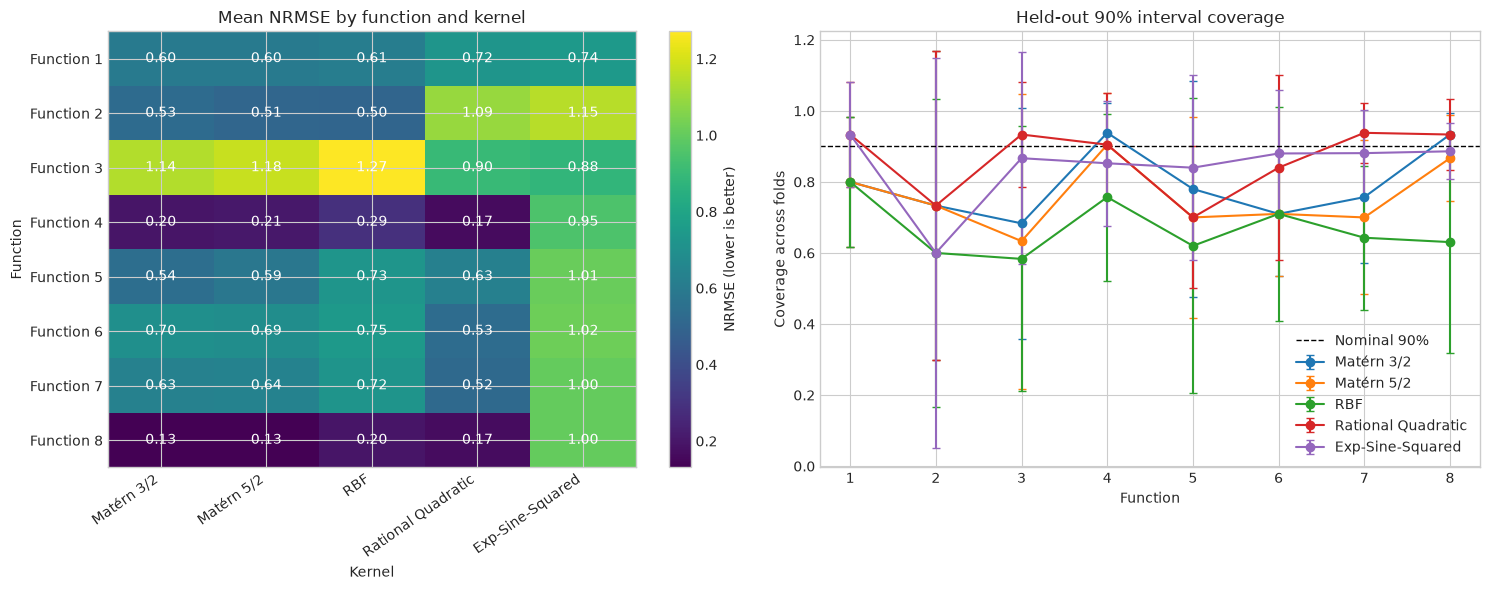

In [6]:
function_ids = sorted(cv_results["function_id"].unique())
kernel_names = list(kernel_factories_by_function[function_ids[0]])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

nrmse_table = cv_summary["NRMSE_mean"].unstack("kernel").reindex(
    index=function_ids,
    columns=kernel_names,
)
image = axes[0].imshow(nrmse_table, aspect="auto", cmap="viridis")
axes[0].set(
    title="Mean NRMSE by function and kernel",
    xlabel="Kernel",
    ylabel="Function",
)
axes[0].set_xticks(range(len(kernel_names)), kernel_names, rotation=35, ha="right")
axes[0].set_yticks(range(len(function_ids)), [f"Function {i}" for i in function_ids])
for row in range(len(function_ids)):
    for column in range(len(kernel_names)):
        axes[0].text(column, row, f"{nrmse_table.iloc[row, column]:.2f}", ha="center", va="center", color="white")
fig.colorbar(image, ax=axes[0], label="NRMSE (lower is better)")

for kernel_name in kernel_names:
    kernel_rows = cv_summary.xs(kernel_name, level="kernel").reindex(function_ids)
    axes[1].errorbar(
        function_ids,
        kernel_rows["coverage_90_mean"],
        yerr=kernel_rows["coverage_90_std"],
        marker="o",
        capsize=3,
        label=kernel_name,
    )
axes[1].axhline(0.90, color="black", linestyle="--", linewidth=1, label="Nominal 90%")
axes[1].set(
    title="Held-out 90% interval coverage",
    xlabel="Function",
    ylabel="Coverage across folds",
    xticks=function_ids,
)
axes[1].legend()
fig.tight_layout()
plt.show()

## Reading the comparison

Compare kernels primarily within each function: NRMSE helps visualize error across different output scales, but it does not make the benchmark functions statistically interchangeable. Coverage near 0.90 is a rough calibration target, and five folds provide only a small number of estimates. Hyperparameters are refit within each fold; results describe prediction on sampled inputs rather than global optimization performance.

## Kernel choice for Notebook 06

Notebook 06 uses Matérn 3/2 for its submission candidates. Following the within-function comparison above, Matérn 3/2 has the lowest mean RMSE across folds among the three benchmark kernels on six of eight functions (Functions 2, 3, 5, 6, 7 and 8). Matérn 5/2 is lower on Function 4. On Function 1 the three kernels differ by less than 0.0001 in RMSE, which is negligible. RBF has the highest RMSE of the three on six of eight functions.

As a secondary summary, averaging NRMSE across functions gives 0.609 for Matérn 3/2, 0.644 for Matérn 5/2 and 0.765 for RBF. Mean 90% coverage is 0.84, 0.81 and 0.66 respectively. The gap to Matérn 5/2 is small relative to the spread across functions and folds. Rational Quadratic has a lower average NRMSE (0.587) and coverage (0.88), but it is a comparison only and does not inform the choice. The in-sample likelihood in Notebook 02 disagrees with this result.